# Extended boosting baseline: recorded results

This notebook reads the small result tables saved in `results/extended_boosting_baseline/`. It does not need the raw data or any model fit.

**Provisional values.** Every pooled five-fold value, every fold-2023 value, and every probability of detection, false alarm ratio and critical success index, is provisional and labelled so below. Three limits (`docs/limitations.md`): (1) fold-2023 numbers use soil-moisture anomaly inputs whose norm includes later 2023 weather; (2) the settings of every model were chosen on scored rows (validation years 2021-2024 for this baseline); (3) the fold-2023 alert threshold was chosen on fold-2024 labels (the other-fold rule of `thresholds()` in `deep_multimodal`). Nothing is removed; corrected numbers will replace these when they exist.

In [1]:
from pathlib import Path
import pandas as pd
RESULTS = Path('..') / 'results' / 'extended_boosting_baseline'
all_arms = pd.read_csv(RESULTS / 'all_arms_by_fold.csv', dtype={'fold': str})
all_arms.shape

(84, 16)

## Extended against plain boosting

The extended version reads 251 inputs: the 42 plain inputs plus 209 weather-window, anomaly and neighbourhood inputs. Average precision (AP) is shown for the same rows and folds.

In [2]:
def provisional(t):
    """Label fold 2023, the pooled five-fold values and the thresholded scores provisional (docs/limitations.md); values are unchanged."""
    m = {f: f'{f} (provisional)' for f in (2023, '2023')}
    m['pooled over the five folds'] = 'pooled over the five folds (provisional)'
    m.update({k: f'{k} (provisional)' for k in ['probability_of_detection', 'false_alarm_ratio', 'critical_success_index']})
    return t.rename(index=m, columns=m)

two = all_arms[all_arms.model.isin(['Plain boosting', 'Extended boosting baseline'])]
table = two.pivot(index='fold', columns='model', values='average_precision')[['Plain boosting', 'Extended boosting baseline']]
table['difference'] = table['Extended boosting baseline'] - table['Plain boosting']
provisional(table).round(4)

model,Plain boosting,Extended boosting baseline,difference
fold,,,
2021,0.1608,0.2035,0.0427
2022,0.2085,0.2264,0.0179
2023 (provisional),0.1528,0.1798,0.0269
2024,0.1807,0.2267,0.0460
2025,0.1863,0.2315,0.0452
pooled over the five folds (provisional),0.1626,0.1977,0.0350


The extended version is ahead on every fold. The pooled row (last) is 0.1977 against 0.1626, and 2025 is 0.2315 against 0.1863.

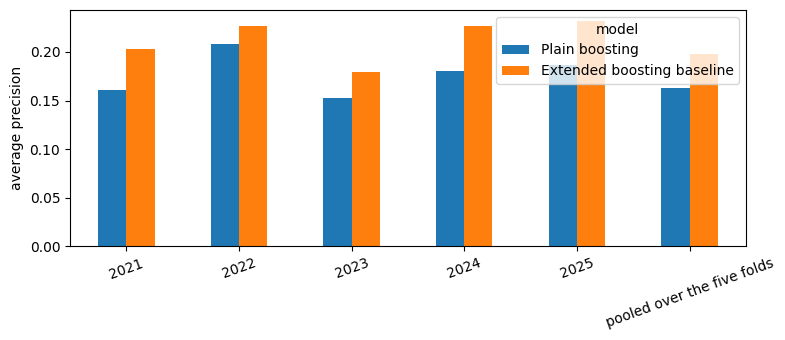

In [3]:
import matplotlib.pyplot as plt
ax = table[['Plain boosting', 'Extended boosting baseline']].plot.bar(figsize=(8, 3.5), rot=20)
ax.set_ylabel('average precision')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

## Every model on the five folds

The reference lines (cell climatology, fire weather index with season) show how much of the skill comes from place and season alone.

In [4]:
all_arms.pivot(index='model', columns='fold', values='average_precision').round(4).sort_values('pooled over the five folds', ascending=False).pipe(provisional)

fold,2021,2022,2023 (provisional),2024,2025,pooled over the five folds (provisional)
model,,,,,,
Extended boosting baseline,0.2035,0.2264,0.1798,0.2267,0.2315,0.1977
Extended network (mean of 10 seeds),0.1776,0.1920,0.1929,0.2134,0.2322,0.1962
Extended logistic (with burn history),0.1692,0.1829,0.1593,0.1817,0.1860,0.1651
Extended logistic (weather and static),0.1694,0.1820,0.1588,0.1813,0.1854,0.1648
Plain boosting,0.1608,0.2085,0.1528,0.1807,0.1863,0.1626
Plain network (mean of 10 seeds),0.1509,0.1588,0.1486,0.1642,0.1837,0.1602
Plain logistic (with burn history),0.1291,0.1426,0.1076,0.1323,0.1304,0.1136
Plain logistic (weather and static),0.1330,0.1329,0.1027,0.1212,0.1229,0.1066
Fire weather index and season,0.1140,0.1289,0.0936,0.1087,0.1194,0.0957


## Paired differences (2025 and pooled)

The interval is a 95% interval from an exact paired bootstrap over week blocks.

In [5]:
pd.read_csv(RESULTS / 'paired_differences.csv')[['fold', 'model', 'compared_with', 'difference', 'interval_low_95', 'interval_high_95']].round(4)

,fold,model,compared_with,difference,interval_low_95,interval_high_95
0,2025,Extended boosting baseline,Plain boosting,0.0452,0.0281,0.0586
1,2025,Extended boosting baseline,Extended logistic (with burn history),0.0456,0.0298,0.0547
2,2025,Extended boosting baseline,Fire weather index and season,0.1122,0.0807,0.1366
3,2025,Plain boosting,Fire weather index and season,0.0670,0.0499,0.0813
4,2025,Extended network (mean of 10 seeds),Extended boosting baseline,0.0006,-0.0142,0.0110
5,2025,Extended boosting baseline,Cell climatology,0.1160,0.0832,0.1355
6,pooled over the five folds,Extended boosting baseline,Plain boosting,0.0350,0.0264,0.0425
7,pooled over the five folds,Extended boosting baseline,Extended logistic (with burn history),0.0325,0.0255,0.0381
8,pooled over the five folds,Extended boosting baseline,Fire weather index and season,0.1019,0.0898,0.1135
9,pooled over the five folds,Plain boosting,Fire weather index and season,0.0669,0.0565,0.0782


## Metric table for 2024 and 2023

One row per fold and group of rows. Only average precision has an interval; every other value is a point estimate. The fold-2023 column and the probability of detection, false alarm ratio and critical success index rows are provisional.

In [6]:
metric = pd.read_csv(RESULTS / 'metric_table_2024_2023.csv')
provisional(metric[metric.stratum == 'all rows'].set_index('fold').T).round(4)

fold,2024,2023 (provisional)
stratum,all rows,all rows
average_precision,0.226737,0.17975
average_precision_within_day,0.193196,0.177509
average_precision_within_cell,0.392685,0.320121
auroc,0.834612,0.805874
auroc_within_day,0.8081,0.779531
auroc_within_cell,0.795727,0.774912
precision_top1pct,0.103308,0.109225
recall_top1pct,0.056676,0.049801
lift_top1pct,6.962245,5.694126


## Where it is weak: the quiet stratum

The quiet stratum holds rows with no neighbouring fire detection in the previous 7 days. Skill there is much lower than over all rows.

In [7]:
provisional(metric[metric.stratum.str.startswith('quiet')].set_index('fold')[['average_precision', 'auroc', 'recall_top5pct', 'brier_skill_score']]).round(4)

,average_precision,auroc,recall_top5pct,brier_skill_score
fold,,,,
2024,0.0343,0.7885,0.2171,0.0713
2023 (provisional),0.0197,0.7259,0.1838,0.0219
